In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import GKSIAS
from psolvers import PGKSIAS

# Toy problem

In [28]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect") # was 10
#A = jlinops.IdentityOperator((n,n))
b = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

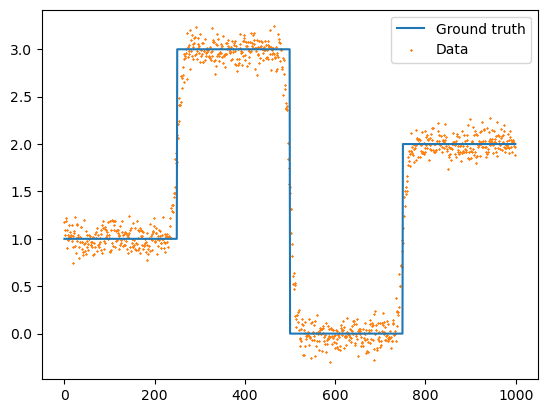

In [29]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, b, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [30]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

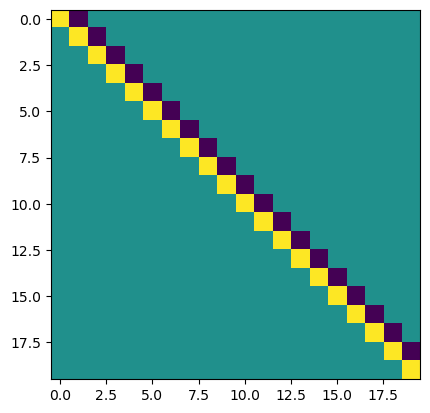

In [31]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Set up methods for comparison (first do convex case)

In [32]:
# # Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
# # _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# # Lpinv_factory = lambda wr: _Lpinv @ jlinops.DiagonalOperator(1.0/wr)

# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

# W = jlinops.MatrixLinearOperator(Wmat)


# # Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
# Atilde = (1.0/noise_stdev)*F
# btilde = (1.0/noise_stdev)*b

# # Solve problem with GKSIAS
# gks_sol3, gks_data3 = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
#                            projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth, 
#                            #regparam_fixed=1.0/gks_data["vartheta_history"][-1]
#                            )
# #variant="modified", fullsize=btilde.size

In [33]:
# TRIPs-Py methods are dp and gcv. The rest I have added. I believe dp is the same as dp3, except uses the GSVD in the formulation of the method whereas dp3 avoids using a GSVD.
# methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv", "mgcv_no_whitening", "gcv_no_whitening", "matlab_gcv_no_whitening" ]
#methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv" ]
#methods = ["dp3"]
#methods = [1e-2, 1e-1, 1e-0, 1e1, 1e2, 1e3, 1e4]
#methods = ["gcv"]
# methods = ["dp2"]
# methods = ["gcv", "matlab_gcv"]
#methods = ["dp3"]
#methods = ["dp", "dp2", "dp3"]
#methods = ["dp3"]
#methods = ["gcv_no_whitening"] 
#methods = ["dp", "my_dp", "gcv", "mgcv", "matlab_gcv"]
# methods = ["my_dp"]
methods = ["dp"]
print(f"Number of methods to compare: {len(methods)}")

Number of methods to compare: 1


In [34]:
import scipy.sparse as sps

# Set problem parameters
n_iters = 120
hyperpr_r = 1
hyperpr_beta = 1.5 + 1e-3
# hyperpr_r = -1
# hyperpr_beta = 1.0

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

#L = jlinops.IdentityOperator((n,n))
#Lpinv_factory = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)
#W = jlinops.MatrixLinearOperator( np.zeros((n,1)) )
#W = None

Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b)

In [35]:
# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    regparam = method
    
    gksias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=8, n_iter=n_iters, regparam=regparam, x_true=ground_truth, x0=None, shift_scale=1.0, regparam_fixed=1e0,
                           err_norm_sq=err_norm_sq)

    # Run the solver
    #data = gksias_solver.solve(n_iter=n_iters, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)

    # Put results into dict
    comp_dct[method] = gksias_data

Started method: dp


running MMGKS...:   7%|▋         | 8/120 [00:00<00:01, 77.06it/s]

1.60469296479153e-25
42.85666372082835
115872.99698343562
Inequality satisfied, there should be a unique positive root!
2538.3431638442394
3.26403032448772e-26
64.75230476862055
115894.8926244834
Inequality satisfied, there should be a unique positive root!
2369.103187056635
8.467534349029189e-26
69.42768658596515
115899.56800630082
Inequality satisfied, there should be a unique positive root!
2328.3201350962645
1.1825005247740336e-25
74.46393659107525
115904.60425630589
Inequality satisfied, there should be a unique positive root!
2406.482924852446
7.092500487422387e-27
82.17905070719382
115912.319370422
Inequality satisfied, there should be a unique positive root!
3024.140599429232
2.1521324193226592e-26
84.4301244032356
115914.57044411796
Inequality satisfied, there should be a unique positive root!
4602.241281670667
7.040297174055499e-26
84.70146622673178
115914.84178594148
Inequality satisfied, there should be a unique positive root!
7098.149299017381
2.6116491428470663e-25
85.811

running MMGKS...:  20%|██        | 24/120 [00:00<00:01, 64.65it/s]

2.065755534445056e-24
95.66470611680506
115925.80502583148
Inequality satisfied, there should be a unique positive root!
31495.7081026798
4.382557729263038e-25
95.61857425135156
115925.75889396611
Inequality satisfied, there should be a unique positive root!
32783.096628055006
2.610121962373561e-25
96.09555038433189
115926.23587009915
Inequality satisfied, there should be a unique positive root!
33946.92557187017
1.5879352076041734e-25
99.73993968056334
115929.88025939536
Inequality satisfied, there should be a unique positive root!
35009.12144977181
2.3194265848271163e-25
101.50840105018187
115931.64872076498
Inequality satisfied, there should be a unique positive root!
35986.7751367534
2.907846474091027e-26
101.64895773655803
115931.78927745124
Inequality satisfied, there should be a unique positive root!
36888.29823506402
1.0919802756809133e-25
101.6557601487774
115931.79607986358
Inequality satisfied, there should be a unique positive root!
37722.163223141804
2.2560521927776497e-24

...

5.115549934596326e-16
163.4063305998825
115993.54665031467
Inequality satisfied, there should be a unique positive root!
55811.9010365872
5.637354151192249e-16
164.4668516199922
115994.60717133486
Inequality satisfied, there should be a unique positive root!


running MMGKS...:  99%|█████████▉| 119/120 [00:06<00:00,  6.97it/s]

55860.163931517585
1.4049719177947454e-16
165.88080702720936
115996.02112674208
Inequality satisfied, there should be a unique positive root!
55908.36509917059


running MMGKS...: 100%|██████████| 120/120 [00:06<00:00, 17.59it/s]

1.8124541357165446e-15
171.5170401829463
116001.65735989767
Inequality satisfied, there should be a unique positive root!
55958.15635762352


# Comparison plots

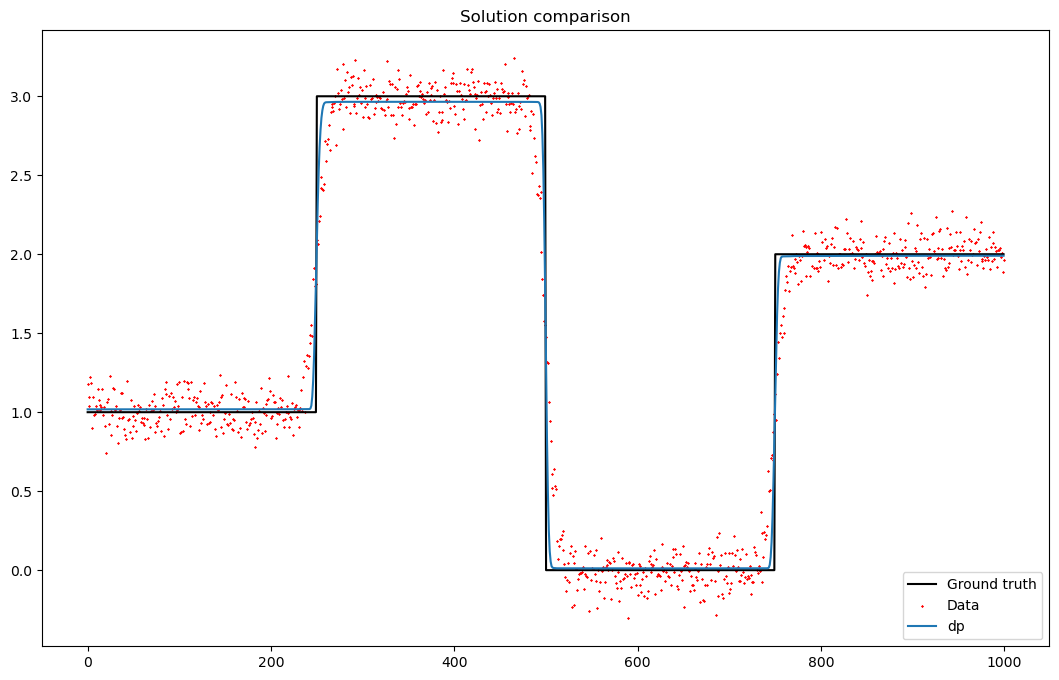

In [36]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data[0], label=method)
    # if method = "dp":
    #     data = comp_dct[method]
    #     plt.plot(grid, data[0], label=method)
    # else:
    #     pass

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

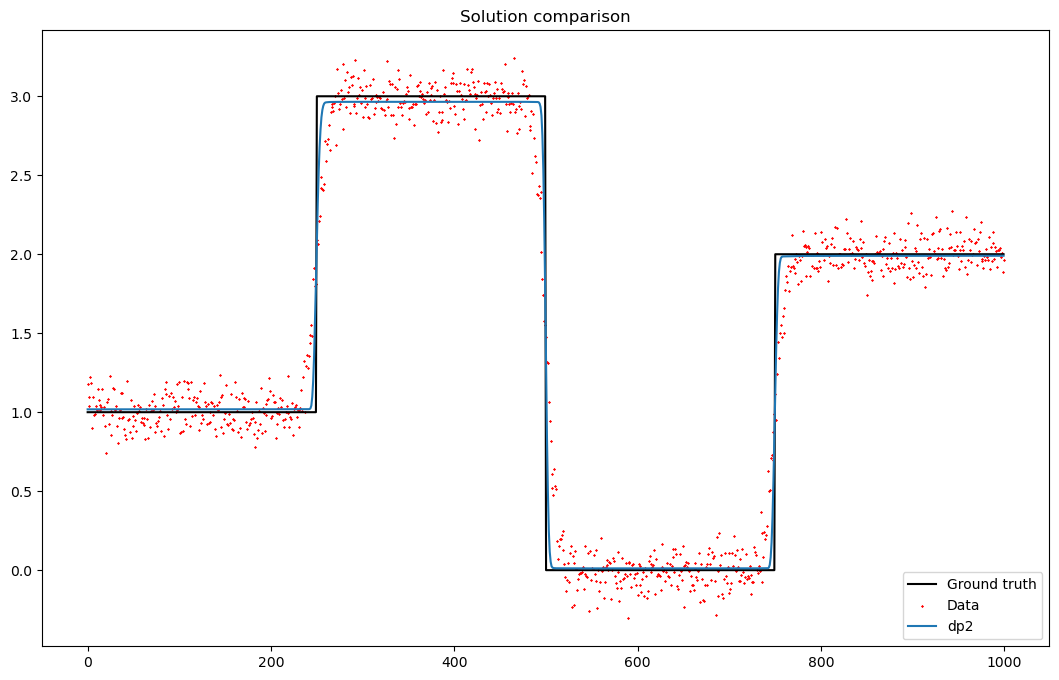

In [11]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    if method != "dp":
        data = comp_dct[method]
        plt.plot(grid, data[0], label=method)
    else:
        pass

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

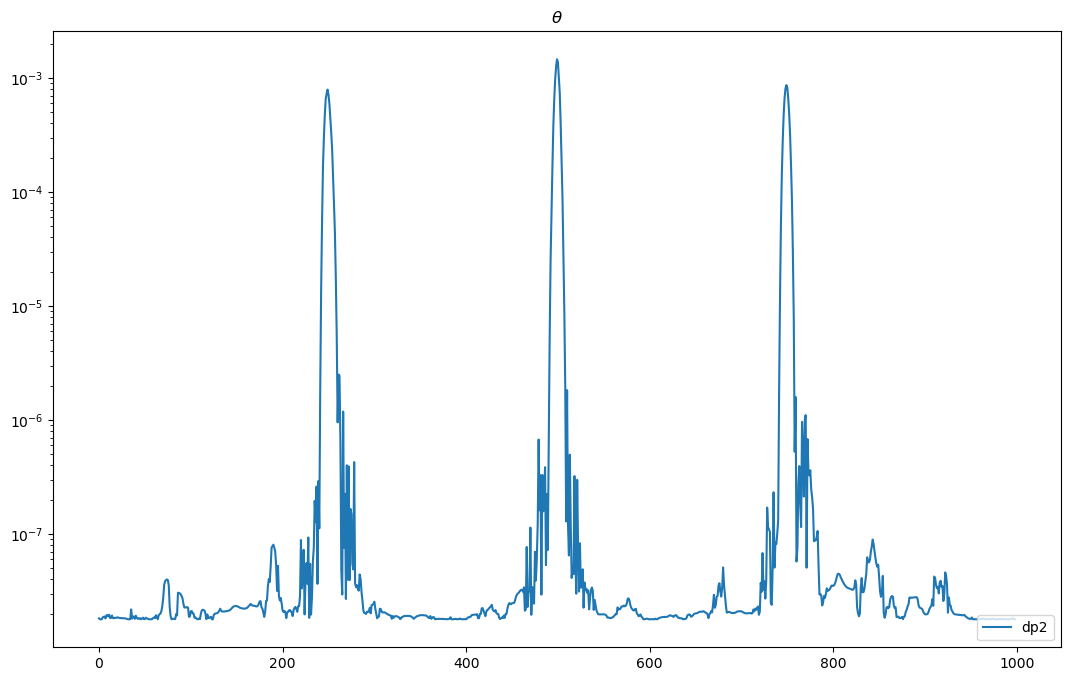

In [12]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(grid[:-1], data[1]["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

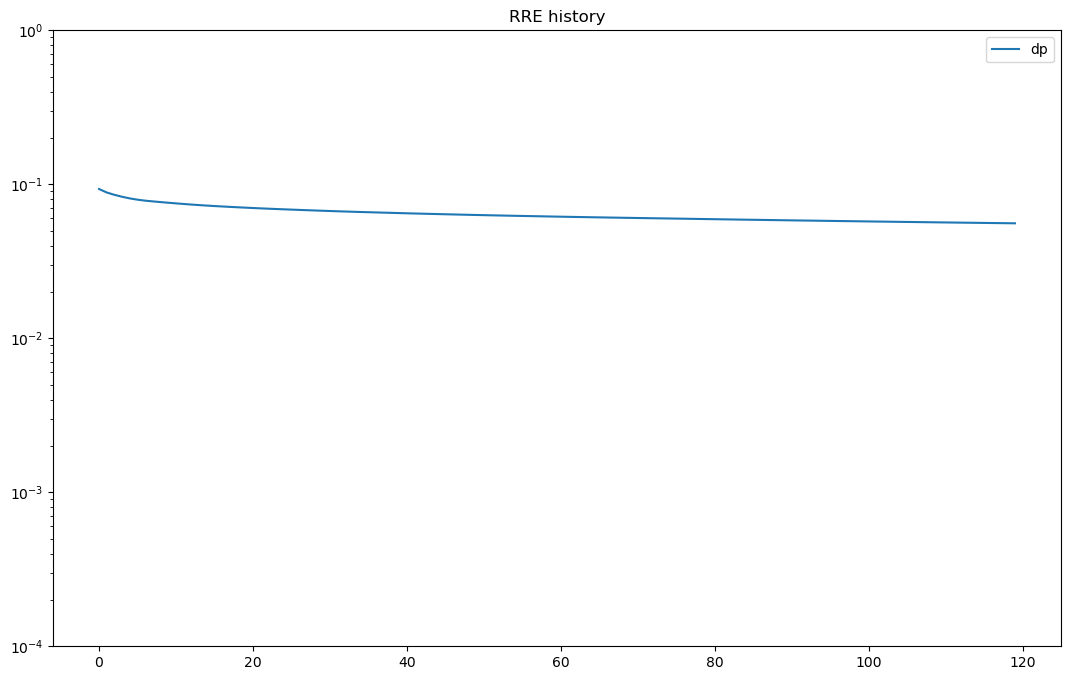

In [37]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data[1]["relError"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.ylim(1e-2, 1e-0)
plt.show()

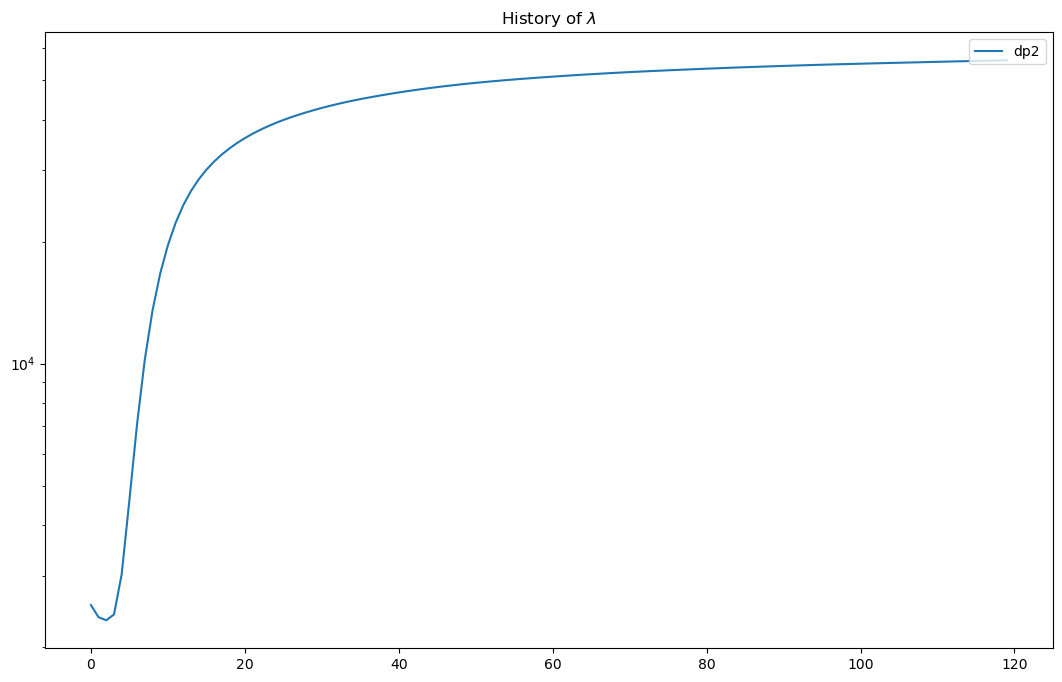

In [14]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data[1]["regParam_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()

In [19]:
data[1]["V"].shape

(999, 128)

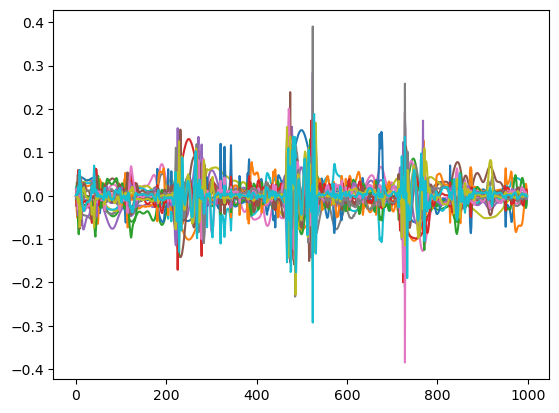

In [20]:
for j in range(20):
    plt.plot(data[1]["V"][:,j] )
plt.show()

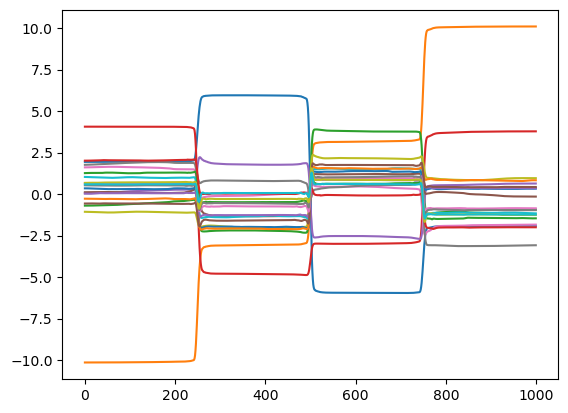

In [21]:
for j in range(20):
    plt.plot( data[1]["LopinvV"][:,j] )
plt.show()

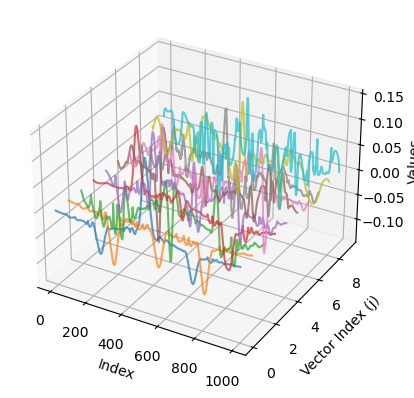

In [25]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Define K (number of column vectors to plot)
K = 10  # For example, plot the first 10 column vectors

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Assuming data[1]["V"] is a 2D array
X = np.arange(data[1]["V"].shape[0])  # X-axis: indices of the vectors
Y = np.arange(min(K, data[1]["V"].shape[1]))  # Y-axis: the varying index (j), limited by K

# Loop through the first K vectors and plot them
for j in range(K):
    ax.plot(X, np.full(X.shape, Y[j]), data[1]["V"][:, j], alpha=0.7)

# Labels (optional)
ax.set_xlabel('Index')
ax.set_ylabel('Vector Index (j)')
ax.set_zlabel('Values')

plt.show()


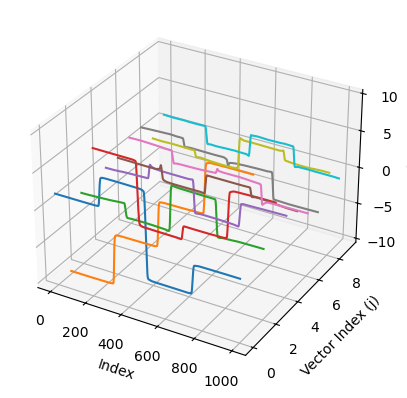

In [23]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Define K (number of column vectors to plot)
K = 10  # For example, plot the first 10 column vectors

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Assuming data[1]["V"] is a 2D array
X = np.arange(data[1]["LopinvV"].shape[0])  # X-axis: indices of the vectors
Y = np.arange(min(K, data[1]["LopinvV"].shape[1]))  # Y-axis: the varying index (j), limited by K

# Loop through the first K vectors and plot them
for j in range(K):
    ax.plot(X, np.full(X.shape, Y[j]), data[1]["LopinvV"][:, j])

# Labels (optional)
ax.set_xlabel('Index')
ax.set_ylabel('Vector Index (j)')
ax.set_zlabel('Values')

plt.show()


# Also do a nonconvex prior?

In [13]:
#methods = ["my_dp", "gcv", "mgcv", "matlab_gcv"]
#method = ["my_dp"]
#methods = ["gcv", "mgcv", "matlab_gcv"]
#methods = ["gcv", "mgcv", "matlab_gcv"]
methods = ["mgcv"]

In [14]:
# Set problem parameters
n_iters = 150
hyperpr_r = -1
hyperpr_beta = 1.0

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    regparam = method
    
    gksias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=5, n_iter=n_iters, regparam=regparam, x_true=ground_truth, x0=ground_truth, shift_scale=1.0, regparam_fixed=1e0,
                           )

    # Run the solver
    #data = gksias_solver.solve(n_iter=n_iters, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)

    # Put results into dict
    comp_dct[method] = gksias_data

Started method: mgcv


running MMGKS...:   5%|▌         | 8/150 [00:00<00:02, 66.68it/s]

999999359840.598
999999358013.3212
999999355531.0913
999999352885.5597
999999540731.8357
999999259794.8683
0.0591582368990803
6.827938985461616e-09
0.03763261938094053
0.02460808437141892
0.05121068974937158
6.413748546082502e-07


running MMGKS...:  10%|█         | 15/150 [00:00<00:02, 55.00it/s]

0.02135969165089122
0.07625131816331446
0.09396021046375
0.09759758788877482
0.07962645874269494
0.05780464505909702
0.02491880125699691
5.186053706756285e-09


...

999999293955.8181


running MMGKS...:  99%|█████████▉| 149/150 [07:17<00:09,  9.79s/it]

999999304776.2966


running MMGKS...: 100%|██████████| 150/150 [07:28<00:00,  2.99s/it]

999999314915.0927


In [16]:
comp_dct.keys()

dict_keys([])

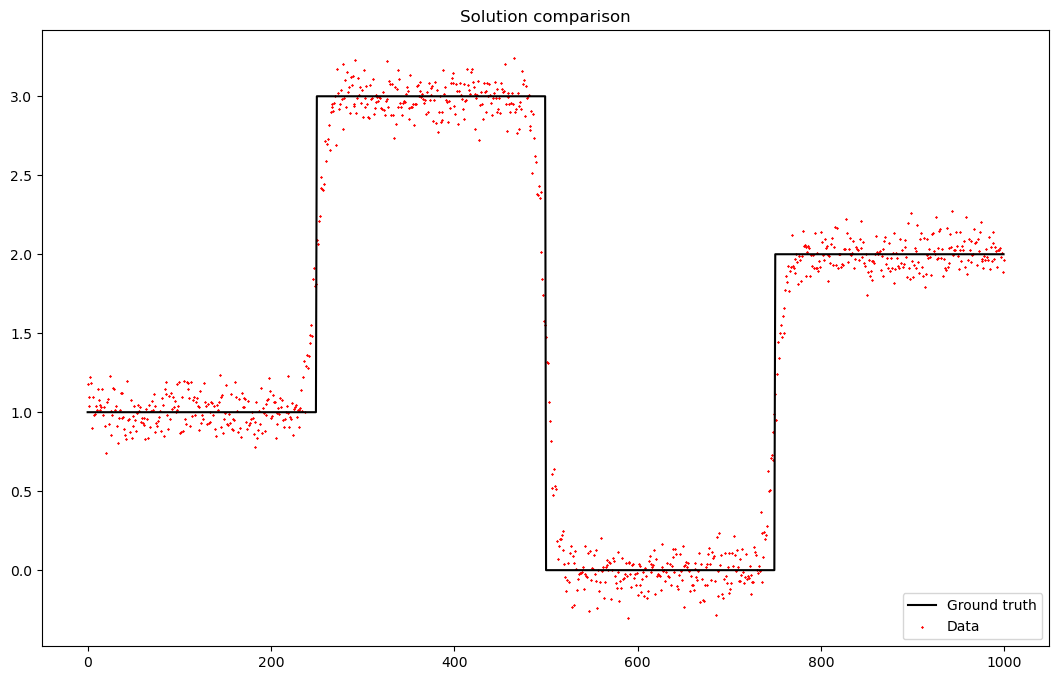

In [15]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data[0], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

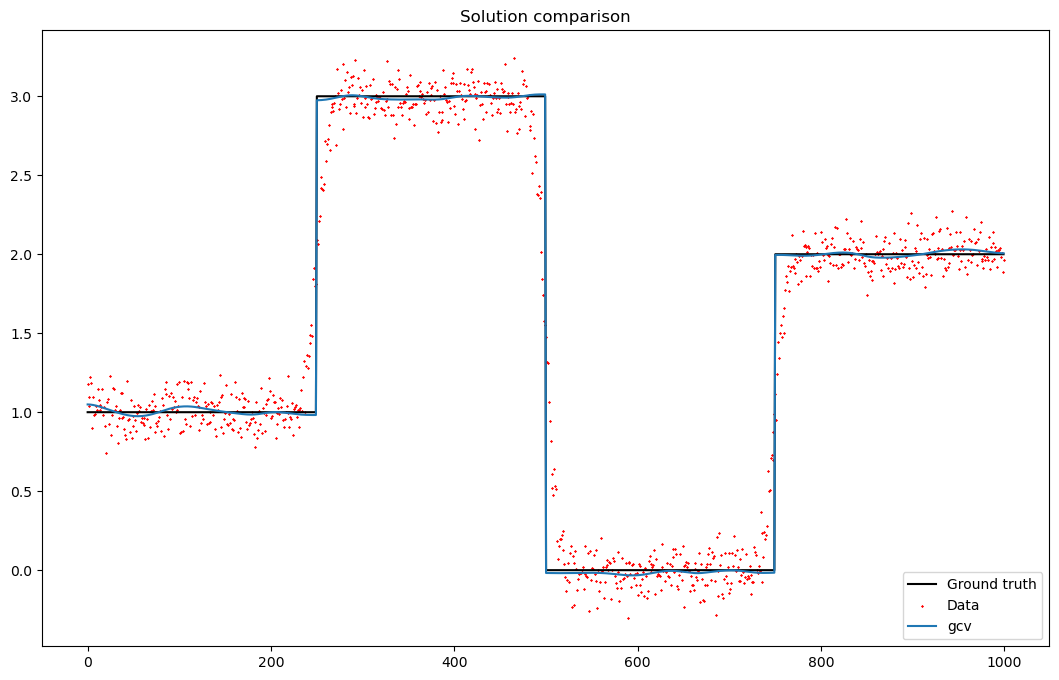

In [11]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data[0], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

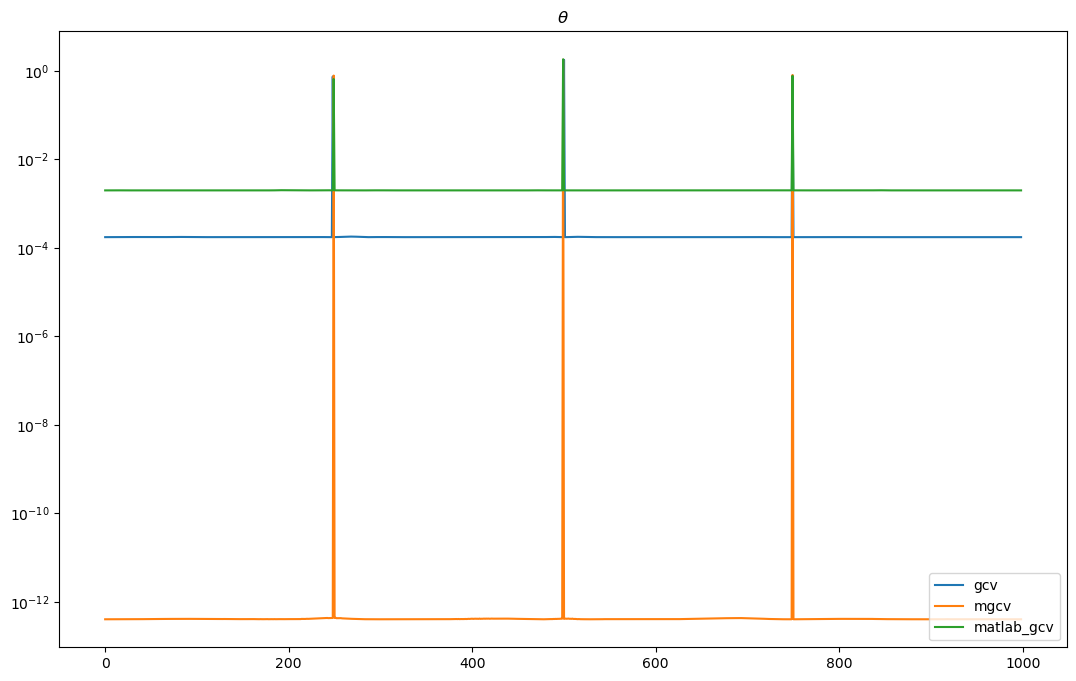

In [30]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method][1]["theta"]
    plt.semilogy(grid[:-1], data, label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

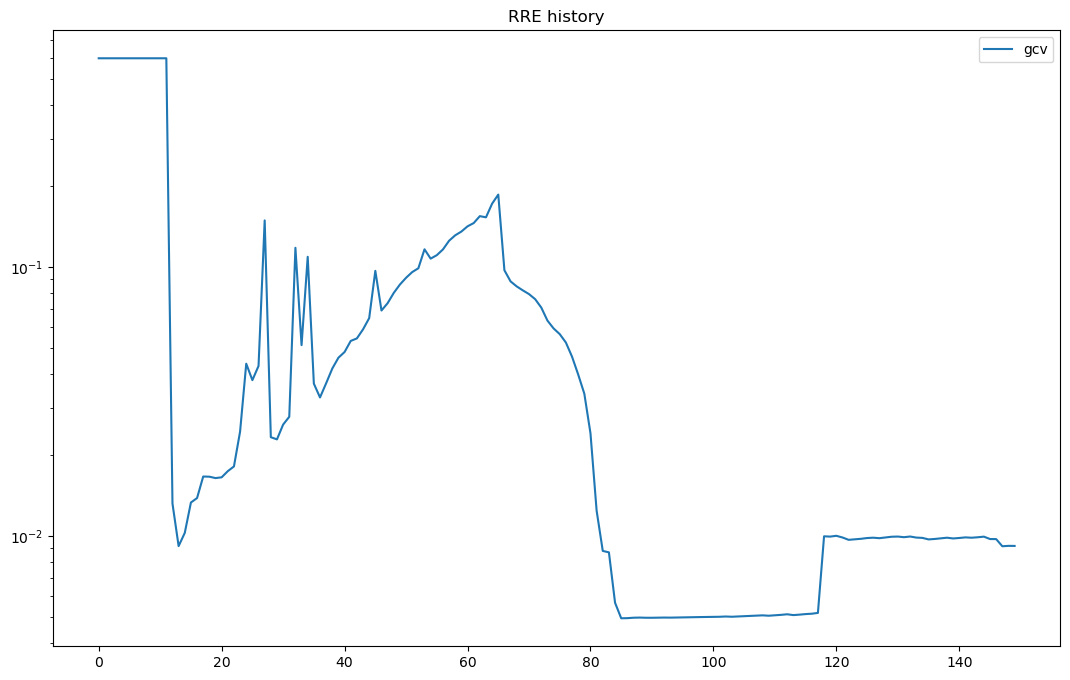

In [12]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method][1]["relError"]
    plt.semilogy(data, label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

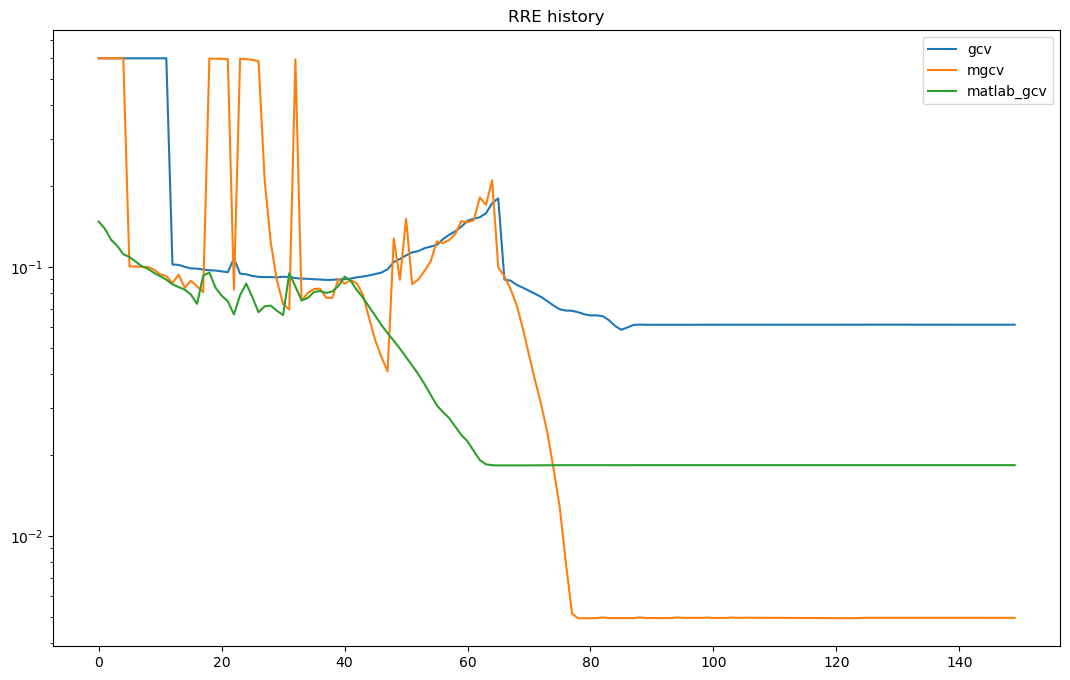

In [32]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method][1]["relError"]
    plt.semilogy(data, label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

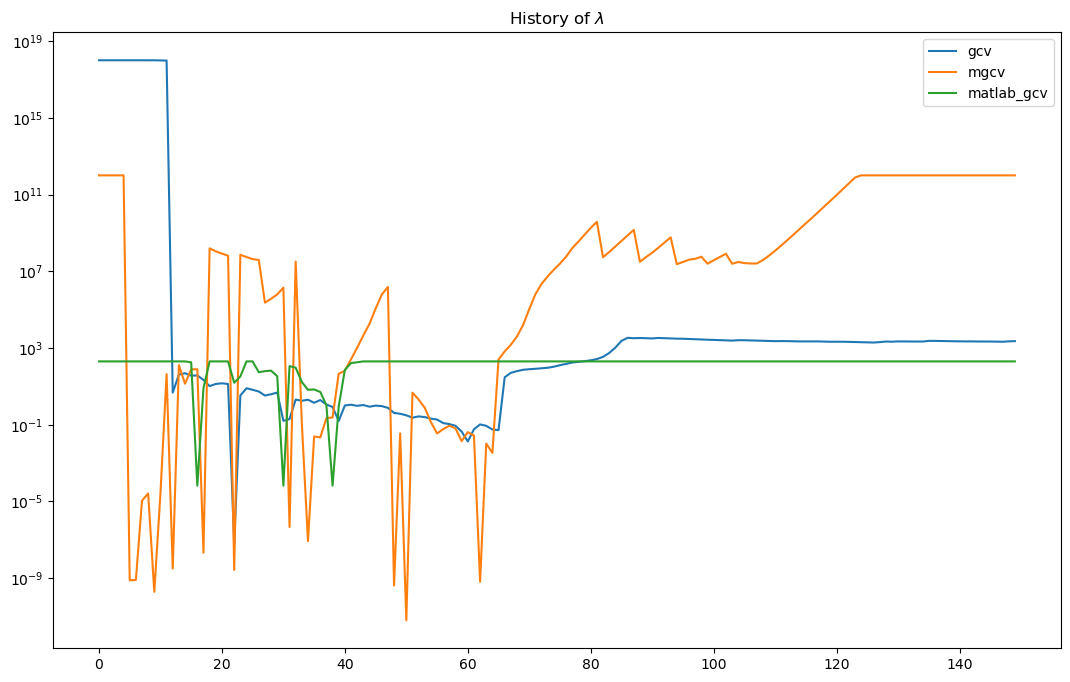

In [33]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    # data = comp_dct[method]
    data = comp_dct[method][1]["regParam_history"]
    plt.semilogy(data, label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()